## TELCO CUSTOMER CHURN
Datasetnya untuk memprediksi apakah  pelanggan akan berhenti berlangganan

## DATA LOADING

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:

import pandas as pd

df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

df.head()


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


Saya menggunakan df.head untuk menampilkan 5 baris teratas saja

In [3]:
df.shape

(7043, 21)

Dataset Telco Customer Churn memiliki 7.034 Baris dan 21 kolom. 20 Fitur dan 1 Target (Churn sebagai targetnya)

In [4]:

df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


Disini terlihat nama **21 kolom** yang terdiri dari fitur dan target, jumlah data tiap kolom serta tipe datanya. Tipe datanya ada int64, float64, dan object

## DATA CLEANING

In [5]:

df.isnull().sum()


customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Berdasarkan hasil pemeriksaan, seluruh kolom menunjukkan nilai kosong sebanyak 0. Awalnya kolom TotalCharges mungkin menunjukkan nilai kosong sebanyak 0 karena beberapa nilainya berbentuk spasi. Jadi, kolom TotalCharges saya periksa lebih lanjut

In [6]:
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

df["TotalCharges"].isnull().sum()

np.int64(11)

Setelah diubah menjadi numerik, ditemukan 11 nilai kosong. Nilai sebelumnya itu tidak terdeteksi sebagai data kosong karna berbentuk spasi

In [7]:
print("Jumlah data kosong sebelum dipisah:")
print(df["TotalCharges"].isnull().sum())

Jumlah data kosong sebelum dipisah:
11


Penanganan nilai kosong ini akan dilakukan setelah pemisahan data latih dan data uji agar terhindar dari data leakage

In [8]:

print("Jumlah data duplikat:", df.duplicated().sum())


Jumlah data duplikat: 0


Tidak ditemukan baris data yang duplikat, jadi tidak ada baris yang perlu dihapus

In [9]:

df = df.drop(columns=["customerID"])

print("Ukuran dataset setelah menghapus customerID:", df.shape)
print(df.columns)


Ukuran dataset setelah menghapus customerID: (7043, 20)
Index(['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure',
       'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity',
       'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV',
       'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod',
       'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')


Kolom CustomerID dihapus karena hanya berisi identitas pelanggan saja dan tidak digunakan sebagai fitur prediksi


Setelah dihapus, dataset yang tadinya memiliki 21 kolom sekarang menjadi 20 kolom. Terdiri dari 19 fitur dan 1 target yaitu Churn. Untuk memastikan kolom customerId sudah terhapus saya menggunakan df.columns yang menampilkan nama-nama kolom yang tersisa pada dataset

## EDA

In [10]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000,7032.000000
mean,0.162147,32.371149,64.761692,2283.300441
std,0.368612,24.559481,30.090047,2266.771362
min,0.000000,0.000000,18.250000,18.800000
25%,0.000000,9.000000,35.500000,401.450000
50%,0.000000,29.000000,70.350000,1397.475000
75%,0.000000,55.000000,89.850000,3794.737500
max,1.000000,72.000000,118.750000,8684.800000


Disini saya menggunakan df.describe untuk melihat hasil perhitungannya. Ada jumlah data sebanyak 7.043, nilai rata-rata (mean), standar deviasi, nilai minimum, kuartil, nilai tengah (median), dan nilai maksimum tiap kolomnya

Churn
No     5174
Yes    1869
Name: count, dtype: int64


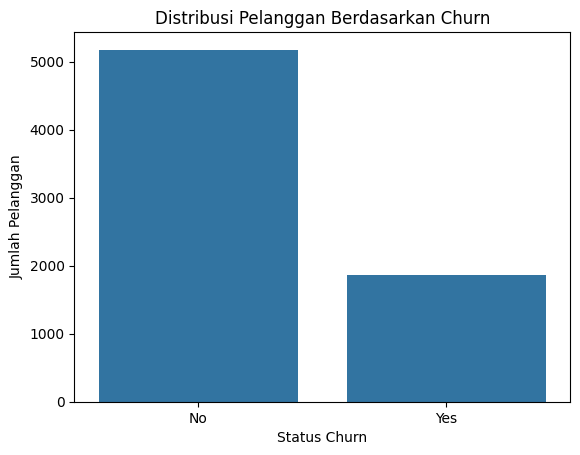

In [11]:
print(df["Churn"].value_counts())

sns.countplot(data=df, x="Churn")
plt.title("Distribusi Pelanggan Berdasarkan Churn")
plt.xlabel("Status Churn")
plt.ylabel("Jumlah Pelanggan")
plt.show()

Grafiknya menunjukkan perbandingan jumlah pelanggan yang berhenti berlangganan (no) dan pelanggan yang masih berlangganan (yes). Nantinya grafik ini bisa membantu mengetahui apakah jumlah data keduanya seimbang 

In [12]:

persentase_churn = df["Churn"].value_counts(normalize=True) * 100

print(persentase_churn.round(2))


Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


Persentasenya dihitung dari jumlah kategori dibagi total pelanggan (7.034) dikalikan 100. Untuk pelanggan dengan status **No** menghasilkan **73,46%** dan pelanggan dengan status **Yes 26,54%**

Data target tidak seimbang karena jumlah pelanggan yang tidak berhenti berlangganan lebih banyak 

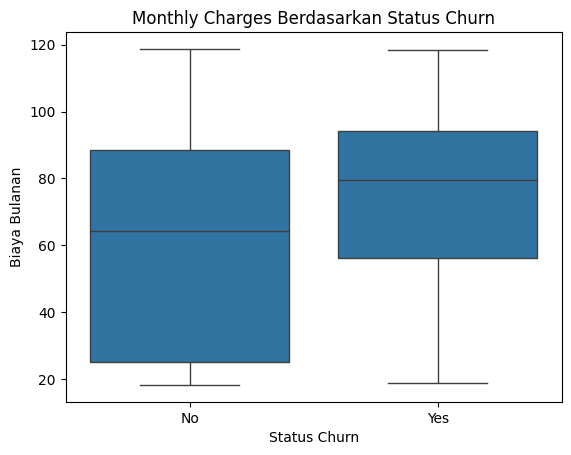

In [13]:

sns.boxplot(data=df, x="Churn", y="MonthlyCharges")
plt.title("Monthly Charges Berdasarkan Status Churn")
plt.xlabel("Status Churn")
plt.ylabel("Biaya Bulanan")
plt.show()


Berdasarkan grafik, pelanggan dengan status Yes memiliki median biaya bulanan yang lebih tinggi dibandingkan pelanggan dengan status No.

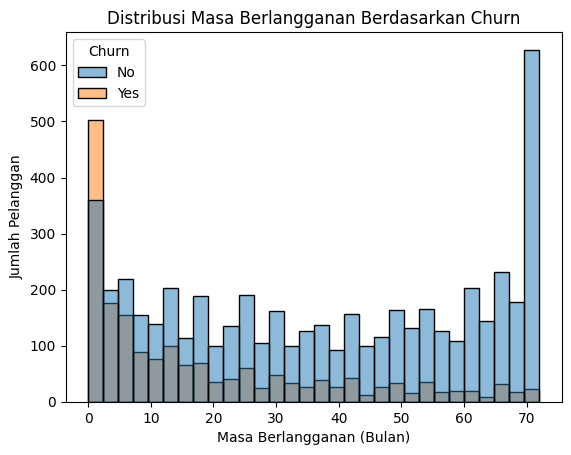

In [14]:
sns.histplot(data=df, x="tenure", hue="Churn", bins=30)
plt.title("Distribusi Masa Berlangganan Berdasarkan Churn")
plt.xlabel("Masa Berlangganan (Bulan)")
plt.ylabel("Jumlah Pelanggan")
plt.show()

Grafik Masa Berlangganan ini menunjukan bahwa pelanggan yang berhenti berlangganan (Yes) lebih banyak pada masa berlangganan yang masih singkat.  Jadi, pelanggan dengan masa berlangganan singkat cenderung lebih rentan mengalami churn

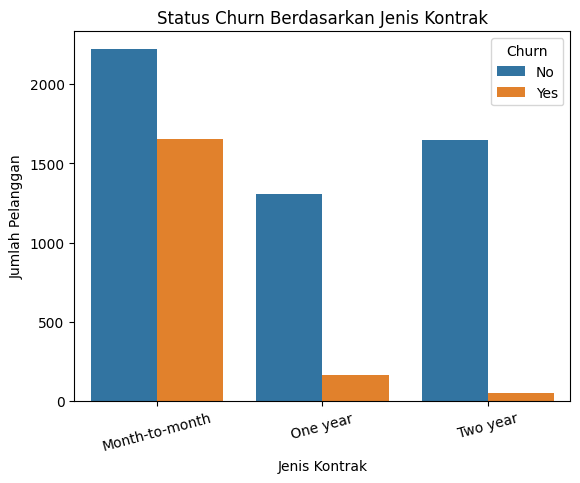

In [15]:
sns.countplot(data=df, x="Contract", hue="Churn")
plt.title("Status Churn Berdasarkan Jenis Kontrak")
plt.xlabel("Jenis Kontrak")
plt.ylabel("Jumlah Pelanggan")
plt.xticks(rotation=15)
plt.show()

Kontrak month-to-month memiliki jumlah pelanggan paling banyak dibanding kontrak one year dan two year. Disisi lain, pelanggan dengan kontrak jangka panjang meemiliki jumlah churn yang lebih sedikit  

## PREPROCESSING

In [16]:
x = df.drop(columns=["Churn"])
y = df["Churn"].map({"No": 0, "Yes": 1})

print("Ukuran fitur:", x.shape)
print("Ukuran target:", y.shape)
print("\nDistribusi target:")
print(y.value_counts())

Ukuran fitur: (7043, 19)
Ukuran target: (7043,)

Distribusi target:
Churn
0    5174
1    1869
Name: count, dtype: int64


Dataset dipisah jadi fitur x dan y. Terdapat 19 fitur yang berisi informasi pelanggan dan 1 target berisi status churn. 

Nilai No diubah menjadi 0 dan Yes menjadi 1 agar target berbentuk numerik dan bisa digunakan untuk pemodelan klasifikasi

In [17]:
x = pd.get_dummies(x, dtype=int)

print("Ukuran fitur setelah encoding:", x.shape)
x.head()

Ukuran fitur setelah encoding: (7043, 45)


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,gender_Female,gender_Male,Partner_No,Partner_Yes,Dependents_No,Dependents_Yes,...,StreamingMovies_Yes,Contract_Month-to-month,Contract_One year,Contract_Two year,PaperlessBilling_No,PaperlessBilling_Yes,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,29.85,29.85,1,0,0,1,1,0,...,0,1,0,0,0,1,0,0,1,0
1,0,34,56.95,1889.50,0,1,1,0,1,0,...,0,0,1,0,1,0,0,0,0,1
2,0,2,53.85,108.15,0,1,1,0,1,0,...,0,1,0,0,0,1,0,0,0,1
3,0,45,42.30,1840.75,0,1,1,0,1,0,...,0,0,1,0,1,0,1,0,0,0
4,0,2,70.70,151.65,1,0,1,0,1,0,...,0,1,0,0,0,1,0,0,1,0


Beberapa fitur masih berisi teks, seperti Gender, Contract, InternetService, dan PaymentMethod diubah terlebih dulu menjadi numerik menggunakan one-hot encoding

Jumlah kolom x akan bertambah karena kolom yang berupa teks tadi sudah diubah menjadi beberapa kolom numerik

## DATA SPLITTING

In [18]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Data latih:", x_train.shape)
print("Data uji:", x_test.shape)

Data latih: (5634, 45)
Data uji: (1409, 45)


Saya membagi data menjadi 80% data latih (train) dan 20% data uji (test).

Data latih = 7043 x 80% = 5634

Data uji 7043 x 20% = 1409

In [19]:
median_total_train = x_train["TotalCharges"].median()

x_train["TotalCharges"] = x_train["TotalCharges"].fillna(median_total_train)
x_test["TotalCharges"] = x_test["TotalCharges"].fillna(median_total_train)

print("Jumlah data kosong di x_train setelah diperbaiki:", x_train["TotalCharges"].isnull().sum())
print("Jumlah data kosong di x_test setelah diperbaiki:", x_test["TotalCharges"].isnull().sum())


Jumlah data kosong di x_train setelah diperbaiki: 0
Jumlah data kosong di x_test setelah diperbaiki: 0


Nilai kosong pada kolom TotalCharges diisi menggunakan nilai median yang dihitung murni hanya dari data latih (x_train), agar data uji (x_test) tetap murni dan model terhindar dari kebocoran data (data leakage)

Distribusi kelas data latih:
Churn
0    4139
1    1495
Name: count, dtype: int64

Persentase kelas data latih:
Churn
0    73.46
1    26.54
Name: proportion, dtype: float64

Imbalance ratio: 2.768561872909699


<Axes: xlabel='Churn', ylabel='count'>

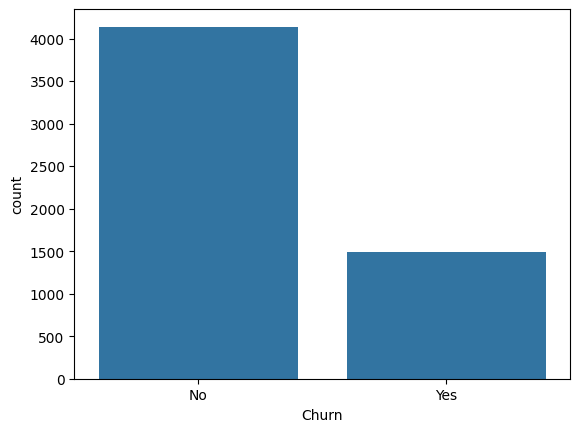

In [20]:
print("Distribusi kelas data latih:")
print(y_train.value_counts())

print("\nPersentase kelas data latih:")
print((y_train.value_counts(normalize=True) * 100).round(2))

vc = y_train.value_counts()
print('\nImbalance ratio:', vc[0]/vc[1])
sns.countplot(x=y_train.map({0:'No', 1:'Yes'}))


Perlu dicari tahu dulu berapa jumlah pelanggan No dan Yes yang masuk ke data latih. Berdasarkan hasil pemeriksaan, terdapar 4.139 pelanggan yang tidak berhenti berlangganan dan 1.495 yang behenti berlangganan

Imbalance ratio = 4.139/1.495 = 2,77 : 1 masih dibawah ambang 4:1 sehingga tidak tergolong ekstrem

Distribusi kelas pada data latih masih tidak seimbang, karena jumlah pelanggan yang tidak berhenti berlangganan lebih banyak dibandingkan pelanggan yang berhenti berlanga

## MODEL DEVELOPMENT & EVALUATION

## Model Tanpa Penangangan Imbalance

In [21]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

model_biasa = RandomForestClassifier(random_state=42)
model_biasa.fit(x_train, y_train)

y_pred_biasa = model_biasa.predict(x_test)

print("Accuracy:", accuracy_score(y_test, y_pred_biasa))
print(classification_report(
    y_test,
    y_pred_biasa,
    target_names=["Tidak Churn", "Churn"]
))

Accuracy: 0.7778566359119943
              precision    recall  f1-score   support

 Tidak Churn       0.82      0.89      0.85      1035
       Churn       0.60      0.48      0.53       374

    accuracy                           0.78      1409
   macro avg       0.71      0.68      0.69      1409
weighted avg       0.77      0.78      0.77      1409



Model Random Forest tanpa penanganan data imbalance memperoleh accuracy sebesar 77,79%. Model ini mampu memprediksi pelanggan yang tidak berhenti berlangganan dengan recall sebesar 89%, tetapi recall pada kelas Churn hanya sebesar 48%

Model ini masih kurang optimal dalam mendeteksi pelanggan yang benar-benar berhenti berlangganan

## Random Forest dengan penanganan imbalance

In [22]:
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(
    random_state=42,
    class_weight="balanced"
)

model.fit(x_train, y_train)

RandomForestClassifier(class_weight='balanced', random_state=42)

Penanganan imbalance data dilakukan menggunakan parameter class_weight="balanced", model dipaksa memberikan perhatian lebih pada data pelanggan yang berhenti berlangganan agar hasil prediksinya lebih adil

In [23]:
y_pred = model.predict(x_test)

print("Hasil prediksi: ")
print(y_pred)

Hasil prediksi: 
[0 1 0 ... 0 0 0]


Model sudah memprediksi status pelanggan pada data uji. Angka 0 prediksi tidak shurn dan angka 1 prediksi churn

In [24]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Tidak Churn", "Churn"]
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy: 0.7828246983676366

Classification Report:
              precision    recall  f1-score   support

 Tidak Churn       0.82      0.90      0.86      1035
       Churn       0.62      0.47      0.53       374

    accuracy                           0.78      1409
   macro avg       0.72      0.68      0.70      1409
weighted avg       0.77      0.78      0.77      1409


Confusion Matrix:
[[928 107]
 [199 175]]


Akurasi 0,7835344215755855 memprediksi sekitar 78% data uji dengan benar

Walau akurasi menjacapai 78,35%, model masih melewatkan cukup banyak pelanggan yang sebenernya churn

## Random forest hasil hyperparameter tuning

In [25]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold

model_rf = RandomForestClassifier(
    random_state=42,
    class_weight="balanced"
)

param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [10, 20, None],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2]
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

grid_search = GridSearchCV(
    estimator=model_rf,
    param_grid=param_grid,
    scoring="f1",
    cv=cv,
    n_jobs=-1,
    verbose=1
)

grid_search.fit(x_train, y_train)

print("Parameter terbaik:")
print(grid_search.best_params_)

print("\nF1-score terbaik saat cross-validation:")
print(grid_search.best_score_)

Fitting 5 folds for each of 24 candidates, totalling 120 fits
Parameter terbaik:
{'max_depth': 10, 'min_samples_leaf': 2, 'min_samples_split': 5, 'n_estimators': 200}

F1-score terbaik saat cross-validation:
0.6313373510732682


In [26]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

best_model = grid_search.best_estimator_

y_pred_tuned = best_model.predict(x_test)

print("Accuracy:", accuracy_score(y_test, y_pred_tuned))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_tuned,
    target_names=["Tidak Churn", "Churn"]
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_tuned))

Accuracy: 0.7615330021291696

Classification Report:
              precision    recall  f1-score   support

 Tidak Churn       0.88      0.78      0.83      1035
       Churn       0.54      0.71      0.61       374

    accuracy                           0.76      1409
   macro avg       0.71      0.75      0.72      1409
weighted avg       0.79      0.76      0.77      1409


Confusion Matrix:
[[806 229]
 [107 267]]


Setelah tuning, recall dan F1-score pada kelas churn meningkat dibandingkan Random Forest awal.

Jika saya tidak pakai Hyperparameter Tuning, nilai Recall Churn model saya rendah sekali, cuma 48%. Artinya, model bawaan pabrik (default) melewatkan lebih dari separuh pelanggan yang mau kabur. Setelah saya lakukan Hyperparameter Tuning, nilai Recall Churn berhasil naik drastis menjadi 71%. Karena itu, saya membandingkan hasilnya dengan model lain sebelum menentukan model yang digunakan

## Model Logistic Regression

In [27]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

# Membuat model Logistic Regression
model_lr = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    )
)

# Melatih model
model_lr.fit(x_train, y_train)

# Prediksi data testing
y_pred_lr = model_lr.predict(x_test)

# Evaluasi model
print("Accuracy:", accuracy_score(y_test, y_pred_lr))
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_lr,
    target_names=["Tidak Churn", "Churn"]
))
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_lr))

Accuracy: 0.7395315826827538

Classification Report:
              precision    recall  f1-score   support

 Tidak Churn       0.90      0.72      0.80      1035
       Churn       0.51      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409


Confusion Matrix:
[[749 286]
 [ 81 293]]


Random Forest awal memiliki accuracy dan precision Churn yang lebih tinggi, sedangkan Logistic Regression lebih baik dalam mendeteksi pelanggan yang benar-benar Churn karena recall dan F1-score Churn-nya lebih tinggi

Logistic Regression lebih sedikit melewatkan pelanggan yang berpotensi berhenti, tetapi lebih banyak memberikan prediksi Churn yang ternyata salah

                             Fitur  Importance
1                           tenure    0.125877
36         Contract_Month-to-month    0.118587
3                     TotalCharges    0.101694
2                   MonthlyCharges    0.073149
18               OnlineSecurity_No    0.062541
38               Contract_Two year    0.061376
27                  TechSupport_No    0.049993
16     InternetService_Fiber optic    0.049967
43  PaymentMethod_Electronic check    0.034725
21                 OnlineBackup_No    0.019864


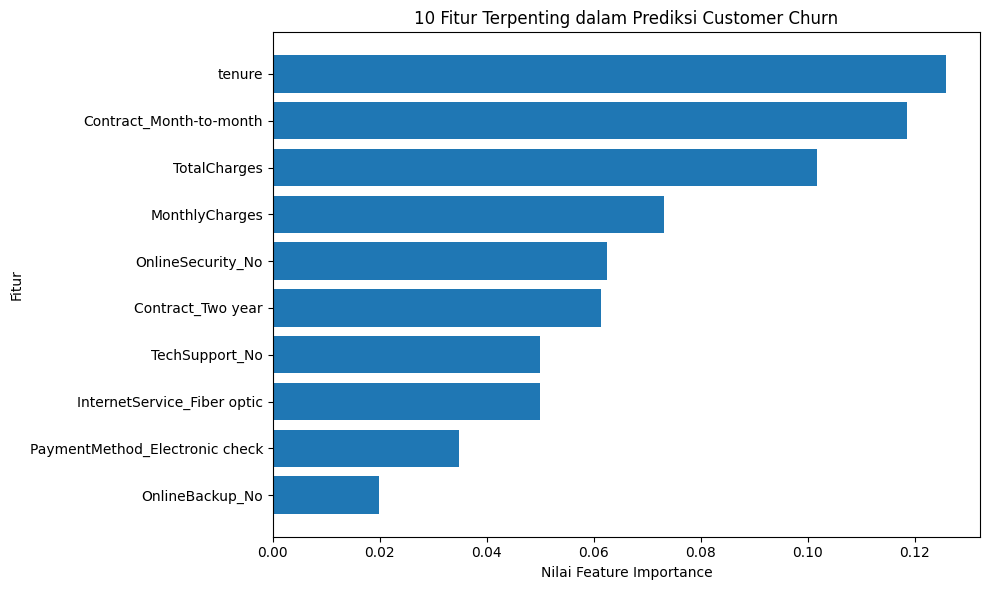

In [30]:
import pandas as pd
import matplotlib.pyplot as plt

# Mengambil model Random Forest hasil tuning
model_final = grid_search.best_estimator_

# Mengambil nilai feature importance
importance = pd.DataFrame({
    "Fitur": x_train.columns,
    "Importance": model_final.feature_importances_
})

# Mengurutkan fitur dari yang paling penting
importance = importance.sort_values(
    by="Importance",
    ascending=False
)

# Menampilkan 10 fitur teratas
print(importance.head(10))

# Membuat grafik
top_10 = importance.head(10).sort_values(
    by="Importance",
    ascending=True
)

plt.figure(figsize=(10, 6))
plt.barh(top_10["Fitur"], top_10["Importance"])
plt.xlabel("Nilai Feature Importance")
plt.ylabel("Fitur")
plt.title("10 Fitur Terpenting dalam Prediksi Customer Churn")
plt.tight_layout()
plt.show()

Fitur tenure memiliki tingkat kepentingan tertinggi dalam memprediksi customer churn. Hal ini menunjukkan bahwa lama waktu pelanggan berlangganan menjadi salah satu faktor penting dalam prediksi pelanggan berhenti berlangganan.

Dilanjut dengan fitur Contract_Month-to-Month yang menunjukkan bahwa jenis kontrak bulanan juga berpengaruh untuk prediksi customer churn

## PERBANDINGAN MODEL

,Model,Accuracy,Precision Churn,Recall Churn,F1-score Churn
0,Random Forest Biasa,0.7779,0.60,0.48,0.53
1,RF + Imbalance Handling,0.7835,0.62,0.47,0.54
2,RF + Hyperparameter Tuning,0.7615,0.54,0.71,0.61
3,Logistic Regression,0.7395,0.51,0.78,0.61


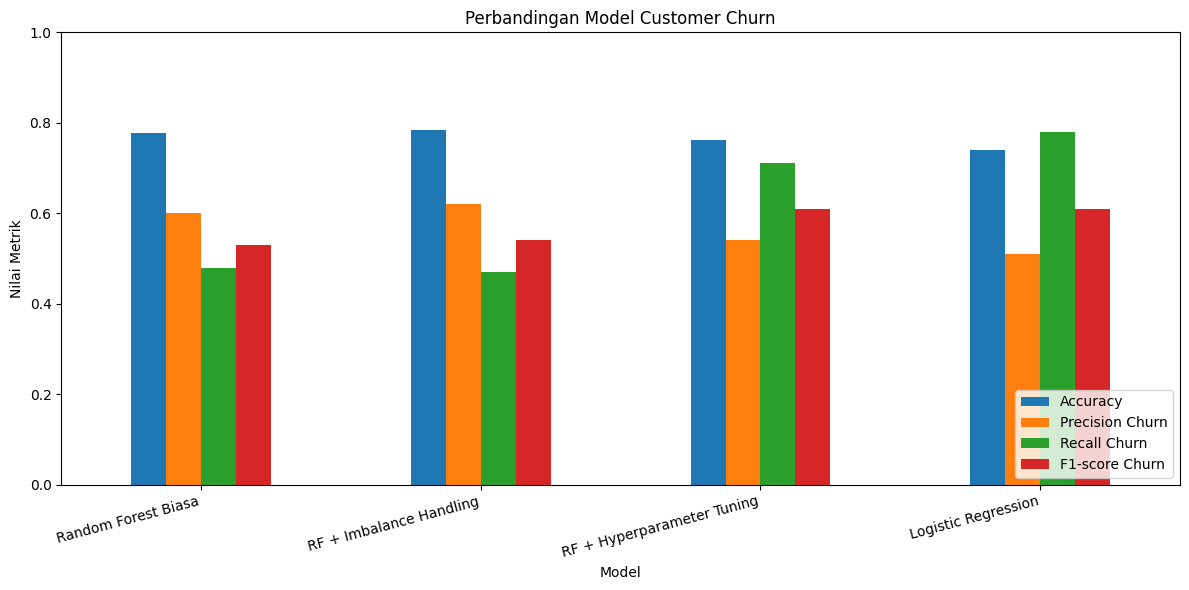

In [31]:
import pandas as pd
import matplotlib.pyplot as plt

# Data perbandingan hasil pengujian model
hasil_model = pd.DataFrame({
    "Model": [
        "Random Forest Biasa",
        "RF + Imbalance Handling",
        "RF + Hyperparameter Tuning",
        "Logistic Regression"
    ],
    "Accuracy": [0.7779, 0.7835, 0.7615, 0.7395],
    "Precision Churn": [0.60, 0.62, 0.54, 0.51],
    "Recall Churn": [0.48, 0.47, 0.71, 0.78],
    "F1-score Churn": [0.53, 0.54, 0.61, 0.61]
})

# Menampilkan tabel perbandingan
display(hasil_model)

# Membuat grafik perbandingan
hasil_model.set_index("Model").plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Perbandingan Model Customer Churn")
plt.xlabel("Model")
plt.ylabel("Nilai Metrik")
plt.xticks(rotation=15, ha="right")
plt.ylim(0, 1)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [35]:
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

model_list = {
    "Random Forest Biasa": model_biasa,
    "RF + Imbalance Handling": model,
    "RF + Hyperparameter Tuning": grid_search.best_estimator_,
    "Logistic Regression": model_lr
}

hasil = []

for nama, mdl in model_list.items():
    prediksi = mdl.predict(x_test)

    hasil.append({
        "Model": nama,
        "Accuracy": accuracy_score(y_test, prediksi),
        "Precision Churn": precision_score(
            y_test, prediksi, zero_division=0
        ),
        "Recall Churn": recall_score(
            y_test, prediksi, zero_division=0
        ),
        "F1-score Churn": f1_score(
            y_test, prediksi, zero_division=0
        )
    })

hasil_model = pd.DataFrame(hasil)

display(hasil_model.round(4))

,Model,Accuracy,Precision Churn,Recall Churn,F1-score Churn
0,Random Forest Biasa,0.7779,0.6034,0.4759,0.5321
1,RF + Imbalance Handling,0.7828,0.6206,0.4679,0.5335
2,RF + Hyperparameter Tuning,0.7615,0.5383,0.7139,0.6138
3,Logistic Regression,0.7395,0.5060,0.7834,0.6149


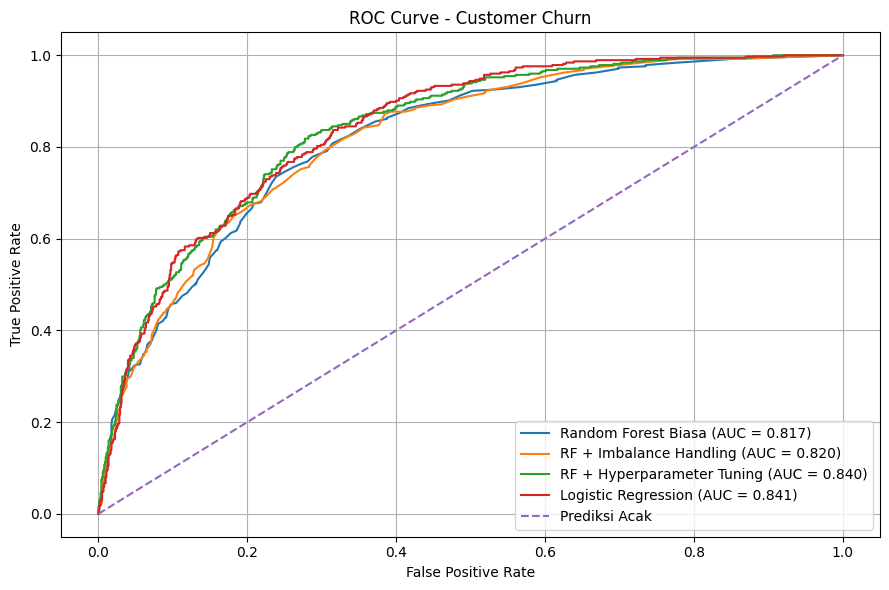

In [37]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

plt.figure(figsize=(9, 6))

for nama, mdl in model_list.items():
    probabilitas = mdl.predict_proba(x_test)[:, 1]

    fpr, tpr, _ = roc_curve(y_test, probabilitas)
    auc = roc_auc_score(y_test, probabilitas)

    plt.plot(fpr, tpr, label=f"{nama} (AUC = {auc:.3f})")

plt.plot([0, 1], [0, 1], "--", label="Prediksi Acak")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Customer Churn")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

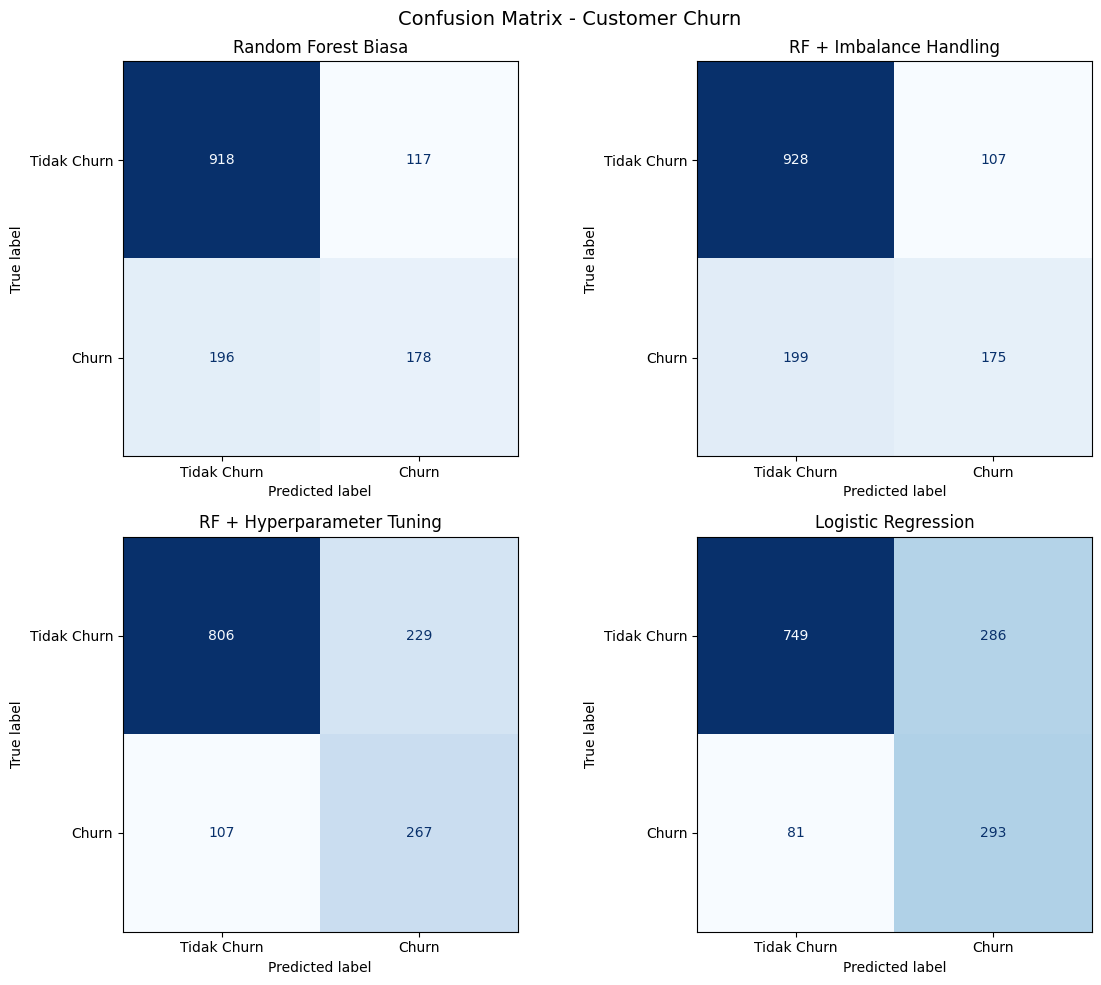

In [39]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for ax, (nama, mdl) in zip(axes.ravel(), model_list.items()):
    ConfusionMatrixDisplay.from_estimator(
        mdl,
        x_test,
        y_test,
        display_labels=["Tidak Churn", "Churn"],
        cmap="Blues",
        ax=ax,
        colorbar=False
    )
    ax.set_title(nama)

plt.suptitle("Confusion Matrix - Customer Churn", fontsize=14)
plt.tight_layout()
plt.show()

## Grafik Confusion Matrix khusus model utama

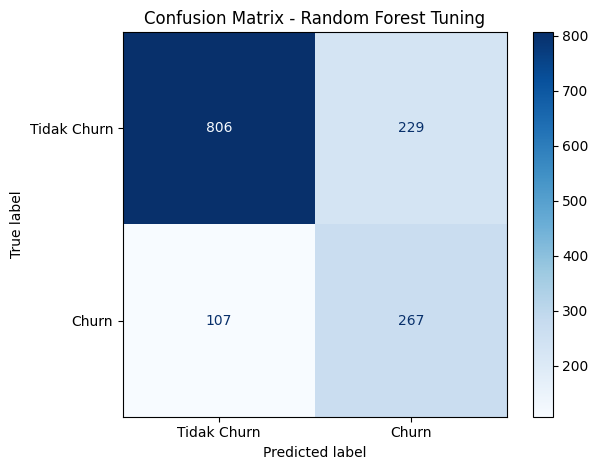

In [41]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_estimator(
    model_final,
    x_test,
    y_test,
    display_labels=["Tidak Churn", "Churn"],
    cmap="Blues"
)

plt.title("Confusion Matrix - Random Forest Tuning")
plt.tight_layout()
plt.show()